In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
datos = pd.read_csv("rmcab_pm25_2009_2015.csv")

In [21]:
datos.columns

Index(['fecha', 'zona', 'estacion', 'unidades', 'pm25_24h', 'hora_24h',
       'pm25_1h', 'hora_1h'],
      dtype='str')

In [22]:
datos.describe()

,pm25_24h,pm25_1h
count,11804.000000,12366.000000
mean,23.430540,40.705070
std,12.437457,23.540721
min,2.600000,0.000000
25%,13.800000,23.300000
50%,21.400000,36.700000
75%,31.400000,53.500000
max,98.600000,315.000000


In [23]:
datos["pm25_24h"].isna()

0         True
1        False
2         True
3        False
4        False
         ...  
27342     True
27343     True
27344    False
27345    False
27346    False
Name: pm25_24h, Length: 27347, dtype: bool

In [24]:
datos.head(15)

,fecha,zona,estacion,unidades,pm25_24h,hora_24h,pm25_1h,hora_1h
0,2009-04-01,WEST,Carvajal - Sevillana,µg/m³,NaN,NaN,NaN,NaN
1,2009-04-01,CENTRAL,Centro de Alto Rendimiento,µg/m³,21.6,01 a.m.,31.4,09 a.m.
2,2009-04-01,NORTH,Guaymaral,µg/m³,NaN,NaN,NaN,NaN
3,2009-04-01,WEST,Kennedy,µg/m³,43.4,01 a.m.,72.7,08 a.m.
4,2009-04-01,NORTH,Las Ferias,µg/m³,22.4,01 a.m.,33.4,07 a.m.
5,2009-04-01,NORTH,MinAmbiente,µg/m³,NaN,NaN,NaN,NaN
6,2009-04-01,WEST,Puente Aranda,µg/m³,NaN,NaN,NaN,NaN
7,2009-04-01,NORTH,Suba,µg/m³,NaN,NaN,NaN,NaN
8,2009-04-01,SOUTH,Tunal,µg/m³,34.6,01 a.m.,68.0,09 a.m.
9,2009-04-01,NORTH,Usaquen,µg/m³,18.9,07 p.m.,32.8,08 a.m.


Convierto la columna fecha al formato correcto

In [25]:
datos["fecha"] = pd.to_datetime(datos["fecha"])

Elimino los datos nulos y fijo la fila (estación) de mayor promedio diario (mayor número en pm25_24h)

In [26]:
datos_validos = datos.dropna(subset=["pm25_24h"])
filas_maximas = datos_validos.loc[datos_validos.groupby("fecha")["pm25_24h"].idxmax()]
filas_maximas

,fecha,zona,estacion,unidades,pm25_24h,hora_24h,pm25_1h,hora_1h
3,2009-04-01,WEST,Kennedy,µg/m³,43.4,01 a.m.,72.7,08 a.m.
13,2009-04-02,WEST,Kennedy,µg/m³,30.9,01 a.m.,39.7,11 p.m.
23,2009-04-03,WEST,Kennedy,µg/m³,41.5,04 p.m.,74.7,07 a.m.
33,2009-04-04,WEST,Kennedy,µg/m³,39.1,01 a.m.,34.3,09 a.m.
43,2009-04-05,WEST,Kennedy,µg/m³,34.1,12 a.m.,56.3,08 a.m.
...,...,...,...,...,...,...,...,...
27289,2015-08-27,WEST,Movil 7ma,µg/m³,41.5,12 p.m.,76.0,12 p.m.
27296,2015-08-28,WEST,Carvajal - Sevillana,µg/m³,39.2,01 a.m.,44.7,01 p.m.
27309,2015-08-29,WEST,Carvajal - Sevillana,µg/m³,32.3,01 a.m.,32.7,03 p.m.
27322,2015-08-30,WEST,Carvajal - Sevillana,µg/m³,26.6,05 a.m.,27.6,04 p.m.


Grafico todas las concentraciones promedio máximas diarias 

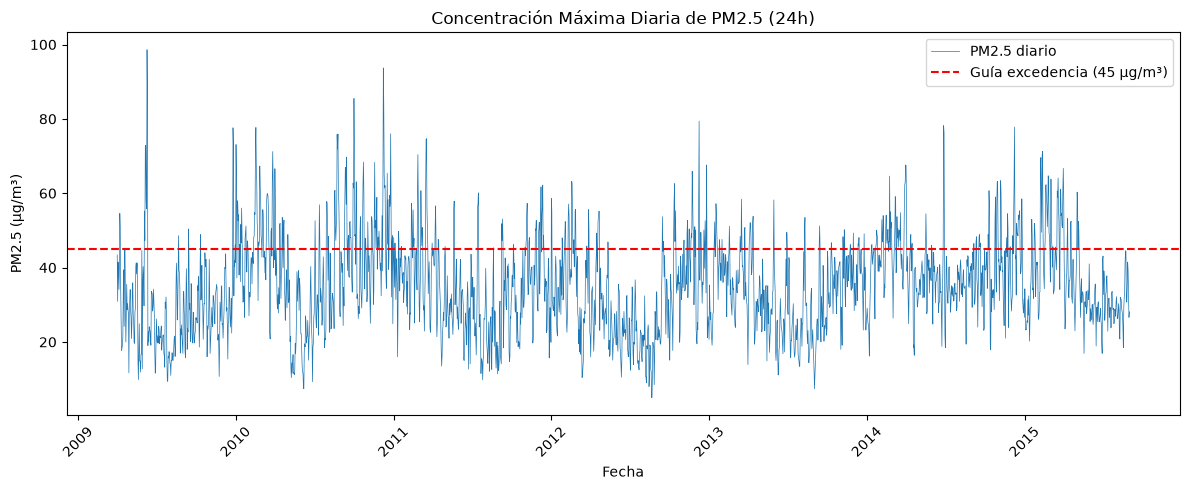

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(filas_maximas['fecha'], filas_maximas['pm25_24h'], linewidth=0.5, label='PM2.5 diario')

# Línea de referencia
plt.axhline(y=45, color='r', linestyle='--', label='Guía excedencia (45 µg/m³)')

# Personalización
plt.title('Concentración Máxima Diaria de PM2.5 (24h)')
plt.xlabel('Fecha')
plt.ylabel('PM2.5 (µg/m³)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [28]:
filas_maximas.describe()

,fecha,pm25_24h,pm25_1h
count,2338,2338.000000,2334.000000
mean,2012-06-14 17:30:44.653550,35.085714,61.004156
min,2009-04-01 00:00:00,5.000000,9.800000
25%,2010-11-06 06:00:00,26.200000,42.000000
50%,2012-06-13 12:00:00,34.000000,56.700000
75%,2014-01-23 18:00:00,42.800000,75.700000
max,2015-08-31 00:00:00,98.600000,315.000000
std,NaN,12.729462,27.206831


Establezco las excedencias con umbral 50, y grafico

(array([13879., 14245., 14610., 14975., 15340., 15706., 16071., 16436.]),
 [Text(13879.0, 0, '2008'),
  Text(14245.0, 0, '2009'),
  Text(14610.0, 0, '2010'),
  Text(14975.0, 0, '2011'),
  Text(15340.0, 0, '2012'),
  Text(15706.0, 0, '2013'),
  Text(16071.0, 0, '2014'),
  Text(16436.0, 0, '2015')])

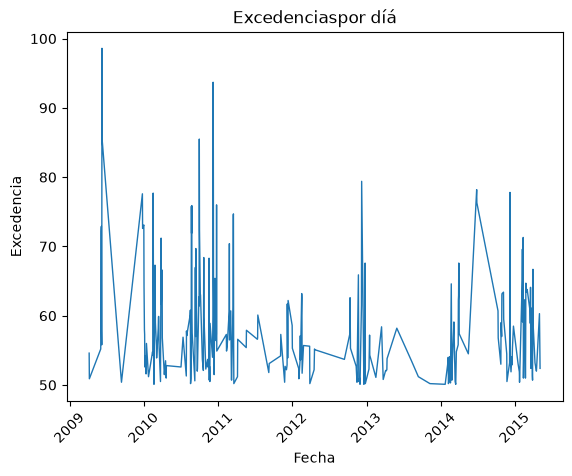

In [29]:
excedencias = filas_maximas[filas_maximas['pm25_24h']>50]
plt.plot(excedencias["fecha"],excedencias["pm25_24h"], linewidth = 1)
plt.title('Excedenciaspor díá')
plt.xlabel('Fecha')
plt.ylabel('Excedencia')
plt.xticks(rotation=45)

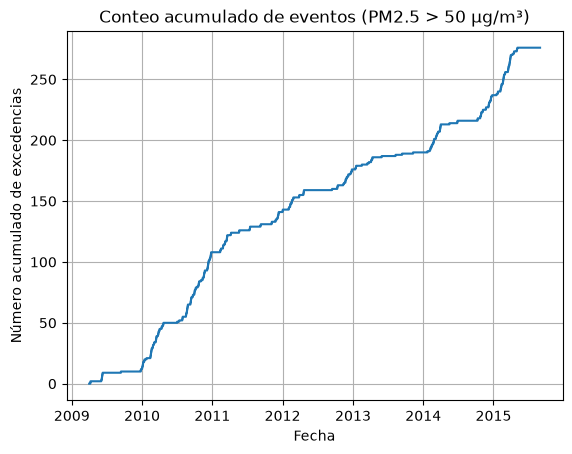

In [30]:
filas_maximas['excedencias_acumuladas'] = (filas_maximas['pm25_24h'] > 50).astype(int).cumsum()

plt.plot(filas_maximas["fecha"], filas_maximas['excedencias_acumuladas'], drawstyle='steps-post')
plt.xlabel("Fecha")
plt.ylabel("Número acumulado de excedencias")
plt.title("Conteo acumulado de eventos (PM2.5 > 50 µg/m³)")
plt.grid(True)
plt.show()

In [31]:
filas_maximas

,fecha,zona,estacion,unidades,pm25_24h,hora_24h,pm25_1h,hora_1h,excedencias_acumuladas
3,2009-04-01,WEST,Kennedy,µg/m³,43.4,01 a.m.,72.7,08 a.m.,0
13,2009-04-02,WEST,Kennedy,µg/m³,30.9,01 a.m.,39.7,11 p.m.,0
23,2009-04-03,WEST,Kennedy,µg/m³,41.5,04 p.m.,74.7,07 a.m.,0
33,2009-04-04,WEST,Kennedy,µg/m³,39.1,01 a.m.,34.3,09 a.m.,0
43,2009-04-05,WEST,Kennedy,µg/m³,34.1,12 a.m.,56.3,08 a.m.,0
...,...,...,...,...,...,...,...,...,...
27289,2015-08-27,WEST,Movil 7ma,µg/m³,41.5,12 p.m.,76.0,12 p.m.,276
27296,2015-08-28,WEST,Carvajal - Sevillana,µg/m³,39.2,01 a.m.,44.7,01 p.m.,276
27309,2015-08-29,WEST,Carvajal - Sevillana,µg/m³,32.3,01 a.m.,32.7,03 p.m.,276
27322,2015-08-30,WEST,Carvajal - Sevillana,µg/m³,26.6,05 a.m.,27.6,04 p.m.,276
